# Lineage gene and peak dynamics

Reusable computations belong in **functions**; the biological choices belong in a **tutorial**. Here we use the new `coati.downstream` functions to select model paths, read observed molecular features, check a local decoder and plot gene/peak dynamics.

The requested example is **NMP → Somitic mesoderm** in gastrulation. NMP annotations first appear at E8.0, so integrate observed E8.0 NMP cells from model time 1 to 2.5 (E8.75). A lineage is defined here by its supplied initial annotations and predicted terminal assignment, not experimental lineage tracing.

**The saved 1,000-step example currently selects no reliable Somitic paths.** The notebook preserves that result; its optional diagnostic curves are explicitly labeled NMP-origin, not NMP → Somitic. Set `MODEL_DIR` to your own matching, validated result to obtain curves for paths that pass the lineage screen.

Run [the gastrulation dynamics tutorial](07_dynamics.ipynb) first. The model and input representations must agree. The reduced benchmark files alone contain neither gene expression nor peaks: this example also reads the existing processed gene/peak H5AD files, read-only. Install `.[notebooks,visualization]`.

In [1]:
from pathlib import Path
import os
import uuid
import json
import hashlib
import numpy as np
import pandas as pd
import anndata as ad
import matplotlib.pyplot as plt
import coati as ct
from coati import downstream as ds

%matplotlib inline
plt.rcParams.update({"font.family": "Arial", "font.size": 11})
project_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
LATENT_DIR = Path(os.environ.get("COATI_GASTRULATION_DATA", project_dir.parent / "TraInfBench/data/processed/gastrulation"))
RAW_DIR = Path(os.environ.get("COATI_GASTRULATION_FEATURES", project_dir.parent / "TraInf/TraInf/Gastrulation/data"))
MODEL_DIR = Path(os.environ.get("COATI_GASTRULATION_RESULT", project_dir / "outputs/gastrulation-dynamics"))
output_dir = Path("outputs") / ("lineage-dynamics-" + uuid.uuid4().hex[:8])
output_dir.mkdir(parents=True, exist_ok=False)
genes = ["T", "Sox2", "Tbx6"]
peaks = ["chr3:34653105-34653705", "chr7:126785067-126785667", "chr7:126785767-126786367"]


## Verify inputs and start from NMP

Use the **same prepared RNA50 and ATAC14 units** as the saved model. `start_time=1.` supplies a later starting cohort explicitly; it does not move E7.5 cells to E8.0. `predict_trajectory` otherwise retains its original default start and integration behavior.

In [2]:
rna = ad.read_h5ad(LATENT_DIR / "rna.h5ad")
atac = ad.read_h5ad(LATENT_DIR / "atac.h5ad")
assert rna.obs_names.is_unique and rna.obs_names.equals(atac.obs_names)
cells = ct.prepare_anndata(
    rna, use_rep="X_latent", time_key="time_point_processed",
    celltype=rna.obs["celltype"].astype(object).fillna("unknown"),
    secondary=atac.obsm["X_latent"], secondary_key="X_atac", warn=False,
)
result = ct.load_result(MODEL_DIR)
for i, time in enumerate(result.data.times):
    mask = np.isclose(cells.obs["time"], time)
    np.testing.assert_array_equal(result.data.primary[i], cells.obsm["X_latent"][mask])
    np.testing.assert_array_equal(result.data.secondary[i], cells.obsm["X_atac"][mask])
initial_mask = (cells.obs["stage"] == "E8.0") & (cells.obs["celltype"] == "NMP")
trajectory = result.predict_trajectory(
    cells.obsm["X_latent"][initial_mask], start_time=1., times=np.linspace(1., 2.5, 16),
)
trajectory["secondary"] = result.project_secondary(trajectory)
initial_barcodes = cells.obs_names[initial_mask].to_numpy(dtype=str)
print("NMP starting cells:", len(initial_barcodes), "Start / end time:", trajectory["times"][[0, -1]])


NMP starting cells: 237 Start / end time: [1.  2.5]


## Select the terminal lineage before molecular interpretation

`select_lineage` compares endpoints to real E8.75 RNA cells, using distance-weighted neighbors. A target vote of at least 0.6 and an empirical neighborhood support check are required. Every assignment and distance is returned, including rejected paths. An empty selection remains empty; changing labels or thresholds to produce a desired curve would not validate a fate.

In [3]:
lineage = ds.select_lineage(
    trajectory, cells, terminal_celltypes="Somitic mesoderm",
    use_rep="X_latent", n_neighbors=15, min_probability=.6,
)
lineage.assignments.insert(1, "initial_barcode", initial_barcodes)
lineage.assignments.to_csv(output_dir / "lineage_assignments.csv", index=False)
print("Accepted NMP → Somitic paths:", len(lineage.indices), "/", len(initial_barcodes))
print("Empirical terminal support distance:", lineage.support_cutoff)
lineage.assignments.groupby("assigned_celltype").agg(paths=("path", "size"), selected=("selected", "sum"))


Accepted NMP → Somitic paths: 0 / 237
Empirical terminal support distance: 0.7834917716195413


,paths,selected
assigned_celltype,,
NMP,203,0
Spinal cord,33,0
unknown,1,0


## Read named genes and peaks in bounded memory

`read_h5ad_features` selects feature columns, verifies unique barcodes and returns rows in the requested order. It streams dense/CSR/CSC files in blocks and does not load the whole gene/peak atlas. No expression normalization is added.

RNA `X` is the source's log-normalized expression. ATAC `X` is a nonnegative count matrix; `binary=True` converts each selected peak to observed presence/absence before fitting a probability readout. The three named peaks are promoter candidates from the existing `nmp_peak_gene_links.csv` (Sox2 and Tbx6). This precomputed annotation table supplies IDs, not proof that these peaks regulate those genes. The gene set is motivated by [published NMP fate work](https://pubmed.ncbi.nlm.nih.gov/28826820/); curves below are not a test of that mechanism.

In [4]:
cache_path = project_dir / "outputs/lineage-nmp-features/observed_features.npz"
signature_path = cache_path.with_name("source_signature.json")
source_signature = {str((RAW_DIR / name).resolve()): {"size": (RAW_DIR / name).stat().st_size,
                    "mtime_ns": (RAW_DIR / name).stat().st_mtime_ns}
                    for name in ["gastrulation_rna_processed.h5ad", "gastrulation_atac_processed.h5ad"]}
if cache_path.exists() and signature_path.exists() and json.loads(signature_path.read_text()) == source_signature:
    # This local cache was extracted from the named source files by the same reader.
    with np.load(cache_path, allow_pickle=False) as cached:
        np.testing.assert_array_equal(cached["barcodes"], cells.obs_names.to_numpy(dtype=str))
        np.testing.assert_array_equal(cached["genes"], genes)
        np.testing.assert_array_equal(cached["peaks"], peaks)
        gene_values, peak_values = cached["rna"].copy(), cached["atac"].copy()
else:
    gene_source = ds.read_h5ad_features(RAW_DIR / "gastrulation_rna_processed.h5ad", genes, obs_names=cells.obs_names)
    peak_source = ds.read_h5ad_features(RAW_DIR / "gastrulation_atac_processed.h5ad", peaks, obs_names=cells.obs_names, binary=True)
    np.testing.assert_array_equal(gene_source.barcodes, peak_source.barcodes)
    gene_values, peak_values = gene_source.values, peak_source.values
print("Observed genes / peaks:", gene_values.shape, peak_values.shape)


Observed genes / peaks: (35503, 3) (35503, 3)


## Fit and test local molecular readouts

PCA/LSI trajectories do not directly contain gene/peak values. Fit separate 30-neighbor decoders in RNA50 and ATAC14, using aligned observed molecular features. The decoder interpolates local observations; it does not invert PCA/LSI.

Reserve 20% of cells per stage for an independent readout check. `validate` scores all test cells against the frozen training-mean baseline and reports neighborhood support separately. For binary peaks, MSE is a **Brier score**; a skill score at or below zero fails to improve the constant observed training open fraction. A supported latent coordinate alone does not establish accurate molecular decoding.

The source PCA/LSI and scales remain fixed and may use the full atlas. This holds observations out of decoder fitting, not preprocessing or vector-field training.

In [5]:
rng = np.random.default_rng(17)
train_rows, test_rows = [], []
for time in np.unique(cells.obs["time"]):
    rows = rng.permutation(np.flatnonzero(cells.obs["time"].to_numpy() == time))
    split = round(.2 * len(rows))
    train_rows.extend(rows[split:])
    test_rows.extend(rows[:split])
train_rows, test_rows = np.array(train_rows), np.array(test_rows)
assert not np.intersect1d(train_rows, test_rows).size
rna_decoder = ds.fit_feature_decoder(
    cells.obsm["X_latent"][train_rows], gene_values[train_rows], features=genes,
    units="Source log-normalized expression",
)
atac_decoder = ds.fit_feature_decoder(
    cells.obsm["X_atac"][train_rows], peak_values[train_rows], features=peaks,
    binary=True, units="Local peak-open probability",
)
gene_quality = rna_decoder.validate(cells.obsm["X_latent"][test_rows], gene_values[test_rows])
peak_quality = atac_decoder.validate(cells.obsm["X_atac"][test_rows], peak_values[test_rows])
gene_quality = gene_quality.rename(columns={"MSE": "squared_error"})
peak_quality = peak_quality.rename(columns={"Brier": "squared_error"})
gene_quality["error_type"], peak_quality["error_type"] = "MSE", "Brier"
gene_quality.insert(0, "modality", "RNA")
peak_quality.insert(0, "modality", "ATAC")
quality = pd.concat([gene_quality, peak_quality], ignore_index=True)
quality.to_csv(output_dir / "readout_validation.csv", index=False)
quality.round(4)


,modality,feature,test_cells,RMSE,baseline_RMSE,squared_error,skill_vs_training_mean,support_coverage,error_type
0,RNA,T,7101,0.3058,0.5244,0.0935,0.6599,0.9882,MSE
1,RNA,Sox2,7101,0.3338,0.4050,0.1114,0.3204,0.9882,MSE
2,RNA,Tbx6,7101,0.1755,0.2155,0.0308,0.3368,0.9882,MSE
3,ATAC,chr3:34653105-34653705,7101,0.2863,0.2835,0.0820,-0.0195,0.9907,Brier
4,ATAC,chr7:126785067-126785667,7101,0.2707,0.3079,0.0733,0.2273,0.9907,Brier
5,ATAC,chr7:126785767-126786367,7101,0.1876,0.1871,0.0352,-0.0050,0.9907,Brier


## Summarize only accepted lineage paths

The main analysis passes `selection=lineage`. `weighting="growth"` uses normalized mass weights within supported selected paths at each time; balanced runs use uniform weights. Returned IQR is spread across interpolated paths, not a molecular confidence interval. Peak curves are **local open probabilities**, not the fraction of predicted cells with a nonzero interpolated value.

An unsupported coordinate becomes NaN and leaves a plot gap. Inspect `summary["coverage"]` and `effective_paths` before interpreting a mean.

In [6]:
weighting = "growth" if "log_weights" in trajectory else "uniform"
if len(lineage.indices):
    lineage_genes = ds.compute_feature_dynamics(rna_decoder, trajectory, selection=lineage, weighting=weighting)
    lineage_peaks = ds.compute_feature_dynamics(atac_decoder, trajectory, modality="secondary", selection=lineage, weighting=weighting)
    ds.plot_feature_dynamics(lineage_genes)
    plt.show()
    ds.plot_feature_dynamics(lineage_peaks, color="#e69f00")
    plt.show()
    lineage_genes.summary.to_csv(output_dir / "lineage_gene_dynamics.csv", index=False)
    lineage_peaks.summary.to_csv(output_dir / "lineage_peak_dynamics.csv", index=False)
else:
    print("No accepted NMP → Somitic lineage in this checkpoint. No lineage-specific molecular curves are reported.")


No accepted NMP → Somitic lineage in this checkpoint. No lineage-specific molecular curves are reported.


## Diagnostic: all NMP-origin paths

For this short checkpoint, inspect the 237 NMP-origin paths separately to see what the current model predicts. These curves **are not a validated NMP → Somitic trajectory**. Black markers show observed E8.0 NMP and later Somitic annotation-cohort means for comparison; these are different observed cohorts, not longitudinal measurements of the same cells.

Two selected peaks fail the readout baseline check; their panels are marked. This illustrates why feature decoding and lineage assignment need separate checks before discussing peak/gene timing or chromatin priming.

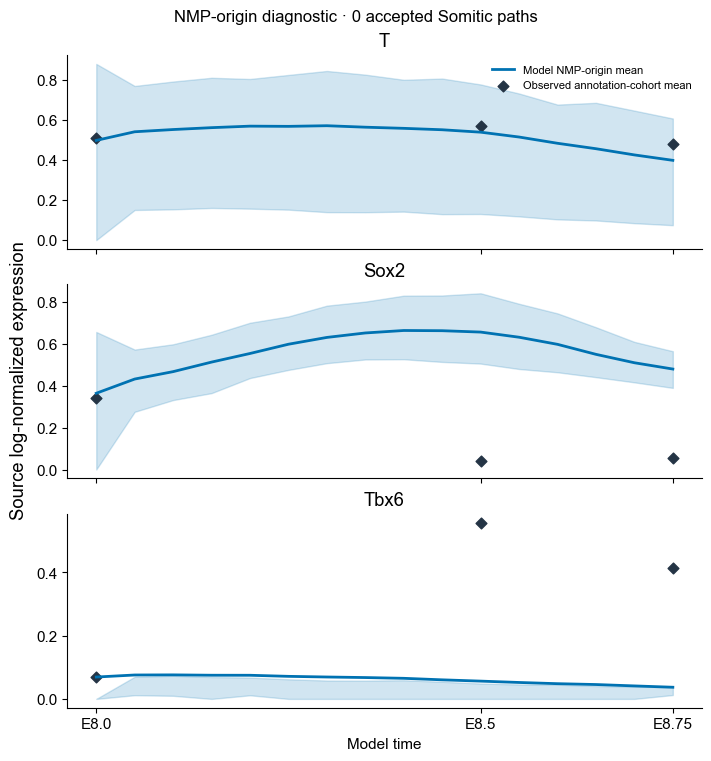

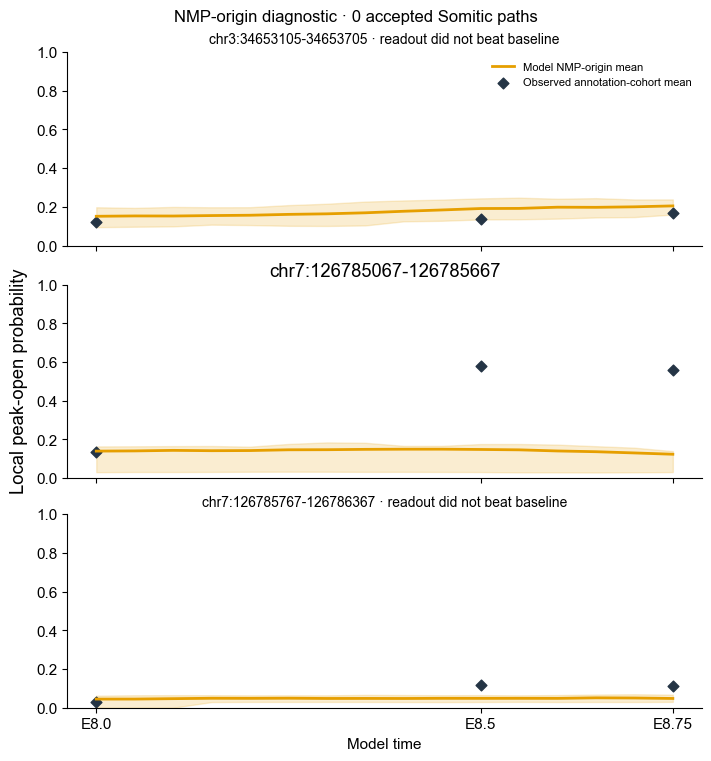

In [7]:
diagnostic_genes = ds.compute_feature_dynamics(rna_decoder, trajectory, weighting=weighting)
diagnostic_peaks = ds.compute_feature_dynamics(atac_decoder, trajectory, modality="secondary", weighting=weighting)
reference_times = [1., 2., 2.5]
reference_types = ["NMP", "Somitic mesoderm", "Somitic mesoderm"]
for dynamics, observed, color, filename in [
    (diagnostic_genes, gene_values, "#0072b2", "diagnostic_genes"),
    (diagnostic_peaks, peak_values, "#e69f00", "diagnostic_peaks"),
]:
    axes = ds.plot_feature_dynamics(dynamics, color=color)
    for j, ax in enumerate(axes):
        reference_means = [observed[np.isclose(cells.obs["time"], t) & (cells.obs["celltype"] == label), j].mean()
                           for t, label in zip(reference_times, reference_types)]
        ax.scatter(reference_times, reference_means, color="#243445", marker="D", s=30, label="Observed annotation-cohort mean")
        ax.lines[0].set_label("Model NMP-origin mean")
        ax.set_xticks(reference_times, ["E8.0", "E8.5", "E8.75"])
        if dynamics.binary and peak_quality.set_index("feature").loc[dynamics.features[j], "skill_vs_training_mean"] <= 0:
            ax.set_title(dynamics.features[j] + " · readout did not beat baseline", fontsize=10)
    axes[0].legend(frameon=False, fontsize=8, loc="upper right")
    axes[0].figure.suptitle(f"NMP-origin diagnostic · {len(lineage.indices)} accepted Somitic paths", fontsize=12)
    axes[0].figure.savefig(output_dir / (filename + ".png"), dpi=180, bbox_inches="tight")
    axes[0].figure.savefig(output_dir / (filename + ".pdf"), bbox_inches="tight")
    plt.show()
    dynamics.summary.to_csv(output_dir / (filename + ".csv"), index=False)


## Heat maps and result records

`plot_feature_heatmap` accepts raw mean units or explicit per-feature z-scores for visualization. A z-score does not make RNA expression and peak probabilities physically comparable and does not establish temporal lead/lag.

Replace gene/peak lists, the initial annotation/time and target endpoint in the cells above for your next lineage. The functions are reusable; genomic links, biological interpretation and model selection remain explicit choices.

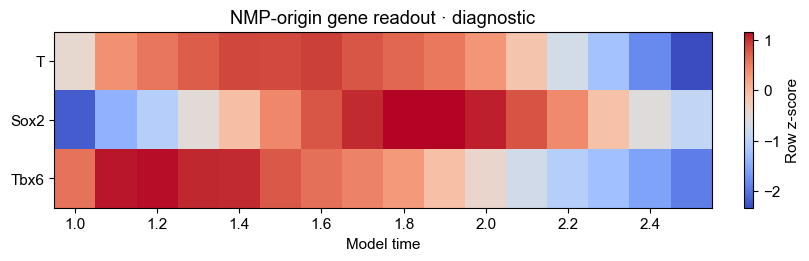

Output: /Users/jingfeng/local/project/COATI/outputs/lineage-dynamics-1b2fe28a


In [8]:
ds.plot_feature_heatmap(diagnostic_genes, standardize=True)
plt.title("NMP-origin gene readout · diagnostic")
plt.gcf().savefig(output_dir / "diagnostic_gene_heatmap.png", dpi=180, bbox_inches="tight")
plt.show()
np.savez_compressed(output_dir / "trajectory.npz", **trajectory, initial_barcodes=initial_barcodes)
report = {
    "requested_lineage": "E8.0 NMP → E8.75 Somitic mesoderm",
    "initial_paths": len(initial_barcodes), "accepted_paths": len(lineage.indices),
    "model_directory": str(MODEL_DIR.resolve()), "model_iterations": result.metadata["config"]["niters"],
    "lineage_threshold": .6, "terminal_support_cutoff": lineage.support_cutoff,
    "readout_test_cells": len(test_rows), "readout_validation": quality.astype(object).where(pd.notna(quality), None).to_dict(orient="records"),
    "gene_support": diagnostic_genes.summary.groupby("time").coverage.first().tolist(),
    "peak_support": diagnostic_peaks.summary.groupby("time").coverage.first().tolist(),
    "weighting": weighting, "genes": genes, "peaks": peaks,
    "molecular_readout": "Distance-weighted interpolation; binary ATAC targets give local open probabilities",
    "scope": "Current short checkpoint has no accepted Somitic branch; NMP-origin diagnostic curves are not lineage validation or evidence of priming.",
}
(output_dir / "downstream_report.json").write_text(json.dumps(report, indent=2, allow_nan=False) + "\n")
print("Output:", output_dir.resolve())
